# Machine Learning-Based Cancer Classification Using Gene Expression Data

An academic, reproducible analysis of UCI dataset 401. Run all cells in order. Results are computed from the real dataset. This is tumour-type classification, not medical diagnosis.

## 1. Setup and project structure
The shared Python scripts keep the notebook and command-line analysis consistent. Seed 42 fixes the split and randomized algorithms. Dependencies are listed in requirements.txt.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import json, platform
from importlib.metadata import version
import pandas as pd
from IPython.display import display, Image
from analysis import *
from load_data import prepare_folders
prepare_folders()
print('Project:', ROOT)

Project: C:\Users\PehAttaJoseph\Documents\ChatGPT\bio-informatics-Uner


## 2. Load and audit the data
The loader first requests `fetch_ucirepo(id=401)` and reads `dataset.data.features` and `dataset.data.targets`. If the API has no downloadable table, it uses the official UCI archive and records the API error and provenance. Cached runs reuse the same snapshot. The audit checks dimensions, label alignment, missing values, finite numeric values and duplicate expression rows. Descriptive statistics are observational; no fitted preprocessing uses the complete dataset.

In [2]:
X, y, audit = load_data()
display(X.iloc[:5, :8])
display(y.value_counts().rename('count').to_frame())
display(X.iloc[:, :8].describe().T)

{
  "samples": 801,
  "features": 20531,
  "missing_feature_values": 0,
  "missing_target_values": 0,
  "duplicate_feature_rows_extra": 0,
  "class_counts": {
    "BRCA": 300,
    "COAD": 78,
    "KIRC": 146,
    "LUAD": 141,
    "PRAD": 136
  },
  "majority_minority_ratio": 3.8461538461538463
}

First five genes - descriptive statistics:
            gene_0      gene_1      gene_2      gene_3      gene_4
count  801.000000  801.000000  801.000000  801.000000  801.000000
mean     0.026642    3.010909    3.095350    6.722305    9.813612
std      0.136850    1.200828    1.065601    0.638819    0.506537
min      0.000000    0.000000    0.000000    5.009284    8.435999
25%      0.000000    2.299039    2.390365    6.303346    9.464466
50%      0.000000    3.143687    3.127006    6.655893    9.791599
75%      0.000000    3.883484    3.802534    7.038447   10.142324
max      1.482332    6.237034    6.063484   10.129528   11.355621

Labels: ['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD']


,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595
sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882
sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982


,count
cancer_class,
BRCA,300
KIRC,146
LUAD,141
PRAD,136
COAD,78


,count,mean,std,min,25%,50%,75%,max
gene_0,801.0,0.026642,0.136850,0.000000,0.000000,0.000000,0.000000,1.482332
gene_1,801.0,3.010909,1.200828,0.000000,2.299039,3.143687,3.883484,6.237034
gene_2,801.0,3.095350,1.065601,0.000000,2.390365,3.127006,3.802534,6.063484
gene_3,801.0,6.722305,0.638819,5.009284,6.303346,6.655893,7.038447,10.129528
gene_4,801.0,9.813612,0.506537,8.435999,9.464466,9.791599,10.142324,11.355621
gene_5,801.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
gene_6,801.0,7.405509,1.108237,3.930747,6.676042,7.450114,8.121984,10.718190
gene_7,801.0,0.499882,0.508799,0.000000,0.000000,0.443076,0.789354,2.779008


## 3. Stratified split and label encoding
We reserve 20% of samples as a test set. Stratification approximately preserves class proportions. LabelEncoder learns the five names from training labels and maps them to integer codes. These codes are categories, not ordered cancer severity. Split membership and label mapping are saved.

In [3]:
X_train, X_test, y_train, y_test, encoder = prepare_split(X, y)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print(dict(enumerate(encoder.classes_)))

Train: (640, 20531) Test: (161, 20531)
{0: 'BRCA', 1: 'COAD', 2: 'KIRC', 3: 'LUAD', 4: 'PRAD'}


## 4. Preprocessing and model definitions
Each pipeline contains training-fitted median imputation, removal of constant genes and ANOVA selection of 500 genes. Logistic Regression and SVM also standardize selected features; Random Forest does not require scaling. Keeping these operations inside the pipeline prevents leakage during cross-validation. The 500-gene choice and model settings were fixed before evaluation; there is no test-driven tuning.

In [4]:
models = build_models()
for name, model in models.items():
    print(name)
    display(model)

Logistic Regression


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will 

Support Vector Machine


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will 

Random Forest


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('variance', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will 

## 5. Cross-validation and model selection
Five stratified training folds estimate accuracy and macro precision, recall and F1. Macro averages give every class equal weight. Every fold fits its own preprocessing. We choose the largest mean macro F1; exact ties favor Logistic Regression, then SVM, then Random Forest. Test results play no part in this decision.

In [5]:
folds, cv_summary, best = compare_cv(X_train, y_train, models)
display(folds)
display(cv_summary)
print('Selected model:', best)

Cross-validation: Logistic Regression


Cross-validation: Support Vector Machine


Cross-validation: Random Forest


,model,fold,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds
0,Logistic Regression,1,1.000000,1.000000,1.000000,1.000000,3.118553
1,Logistic Regression,2,1.000000,1.000000,1.000000,1.000000,2.879141
2,Logistic Regression,3,1.000000,1.000000,1.000000,1.000000,2.763198
3,Logistic Regression,4,0.992188,0.995918,0.990909,0.993287,2.843342
4,Logistic Regression,5,1.000000,1.000000,1.000000,1.000000,2.947542
5,Support Vector Machine,1,1.000000,1.000000,1.000000,1.000000,2.819383
6,Support Vector Machine,2,1.000000,1.000000,1.000000,1.000000,2.760920
7,Support Vector Machine,3,1.000000,1.000000,1.000000,1.000000,2.821882
8,Support Vector Machine,4,0.992188,0.995918,0.990909,0.993287,2.627534
9,Support Vector Machine,5,0.992188,0.995918,0.991304,0.993494,2.545974


,cv_accuracy_mean,cv_accuracy_std,cv_precision_macro_mean,cv_precision_macro_std,cv_recall_macro_mean,cv_recall_macro_std,cv_f1_macro_mean,cv_f1_macro_std,tie_priority
model,,,,,,,,,
Logistic Regression,0.998437,0.003494,0.999184,0.001825,0.998182,0.004066,0.998657,0.003002,0
Support Vector Machine,0.996875,0.004279,0.998367,0.002236,0.996443,0.004873,0.997356,0.003621,1
Random Forest,0.996875,0.004279,0.998367,0.002236,0.996443,0.004873,0.997356,0.003621,2


Selected model: Logistic Regression


## 6. Held-out evaluation
The frozen specifications are fitted to the training subset and evaluated on the held-out test subset. Complete pipelines, label encoders, per-class metrics, confusion matrices and predictions are saved. Cross-validation fold SD measures fold variability; it is not a confidence interval or proof of superiority.

In [6]:
fitted, metrics = evaluate_models(X_train, X_test, y_train, y_test, encoder, models)
display(metrics)
for name in models:
    slug = name.lower().replace(' ', '_')
    print(name)
    display(pd.read_csv(TABLES / f'confusion_{slug}.csv', index_col=0))

Final training and test evaluation: Logistic Regression


Final training and test evaluation: Support Vector Machine


Final training and test evaluation: Random Forest


,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds
model,,,,,
Logistic Regression,0.993789,0.996721,0.992857,0.994711,3.335891
Support Vector Machine,0.993789,0.996721,0.992857,0.994711,2.978657
Random Forest,0.987578,0.993548,0.985714,0.989314,3.728002


Logistic Regression


,BRCA,COAD,KIRC,LUAD,PRAD
BRCA,60,0,0,0,0
COAD,0,16,0,0,0
KIRC,0,0,30,0,0
LUAD,1,0,0,27,0
PRAD,0,0,0,0,27


Support Vector Machine


,BRCA,COAD,KIRC,LUAD,PRAD
BRCA,60,0,0,0,0
COAD,0,16,0,0,0
KIRC,0,0,30,0,0
LUAD,1,0,0,27,0
PRAD,0,0,0,0,27


Random Forest


,BRCA,COAD,KIRC,LUAD,PRAD
BRCA,60,0,0,0,0
COAD,0,16,0,0,0
KIRC,0,0,30,0,0
LUAD,2,0,0,26,0
PRAD,0,0,0,0,27


## 7. Professional figures and feature importance
PCA is a separate unsupervised view of all nonconstant genes. Its scaling and components are fitted only on training data; test points are projected. The two PCs are not used as classifier features. The Random Forest plot reports training impurity importance among selected genes. Anonymous feature names cannot establish gene functions, causal drivers or biomarkers.

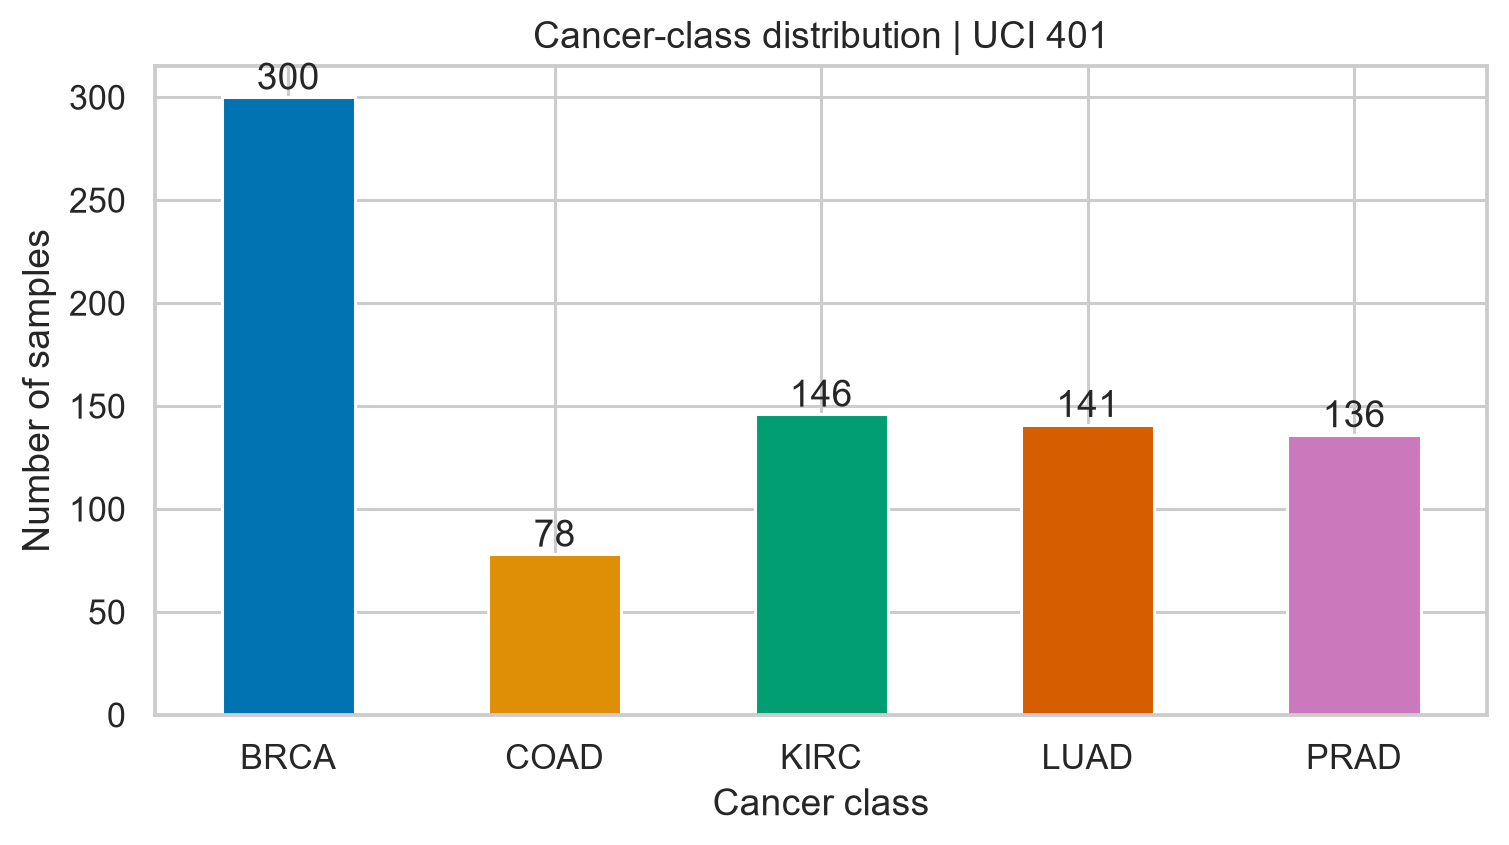

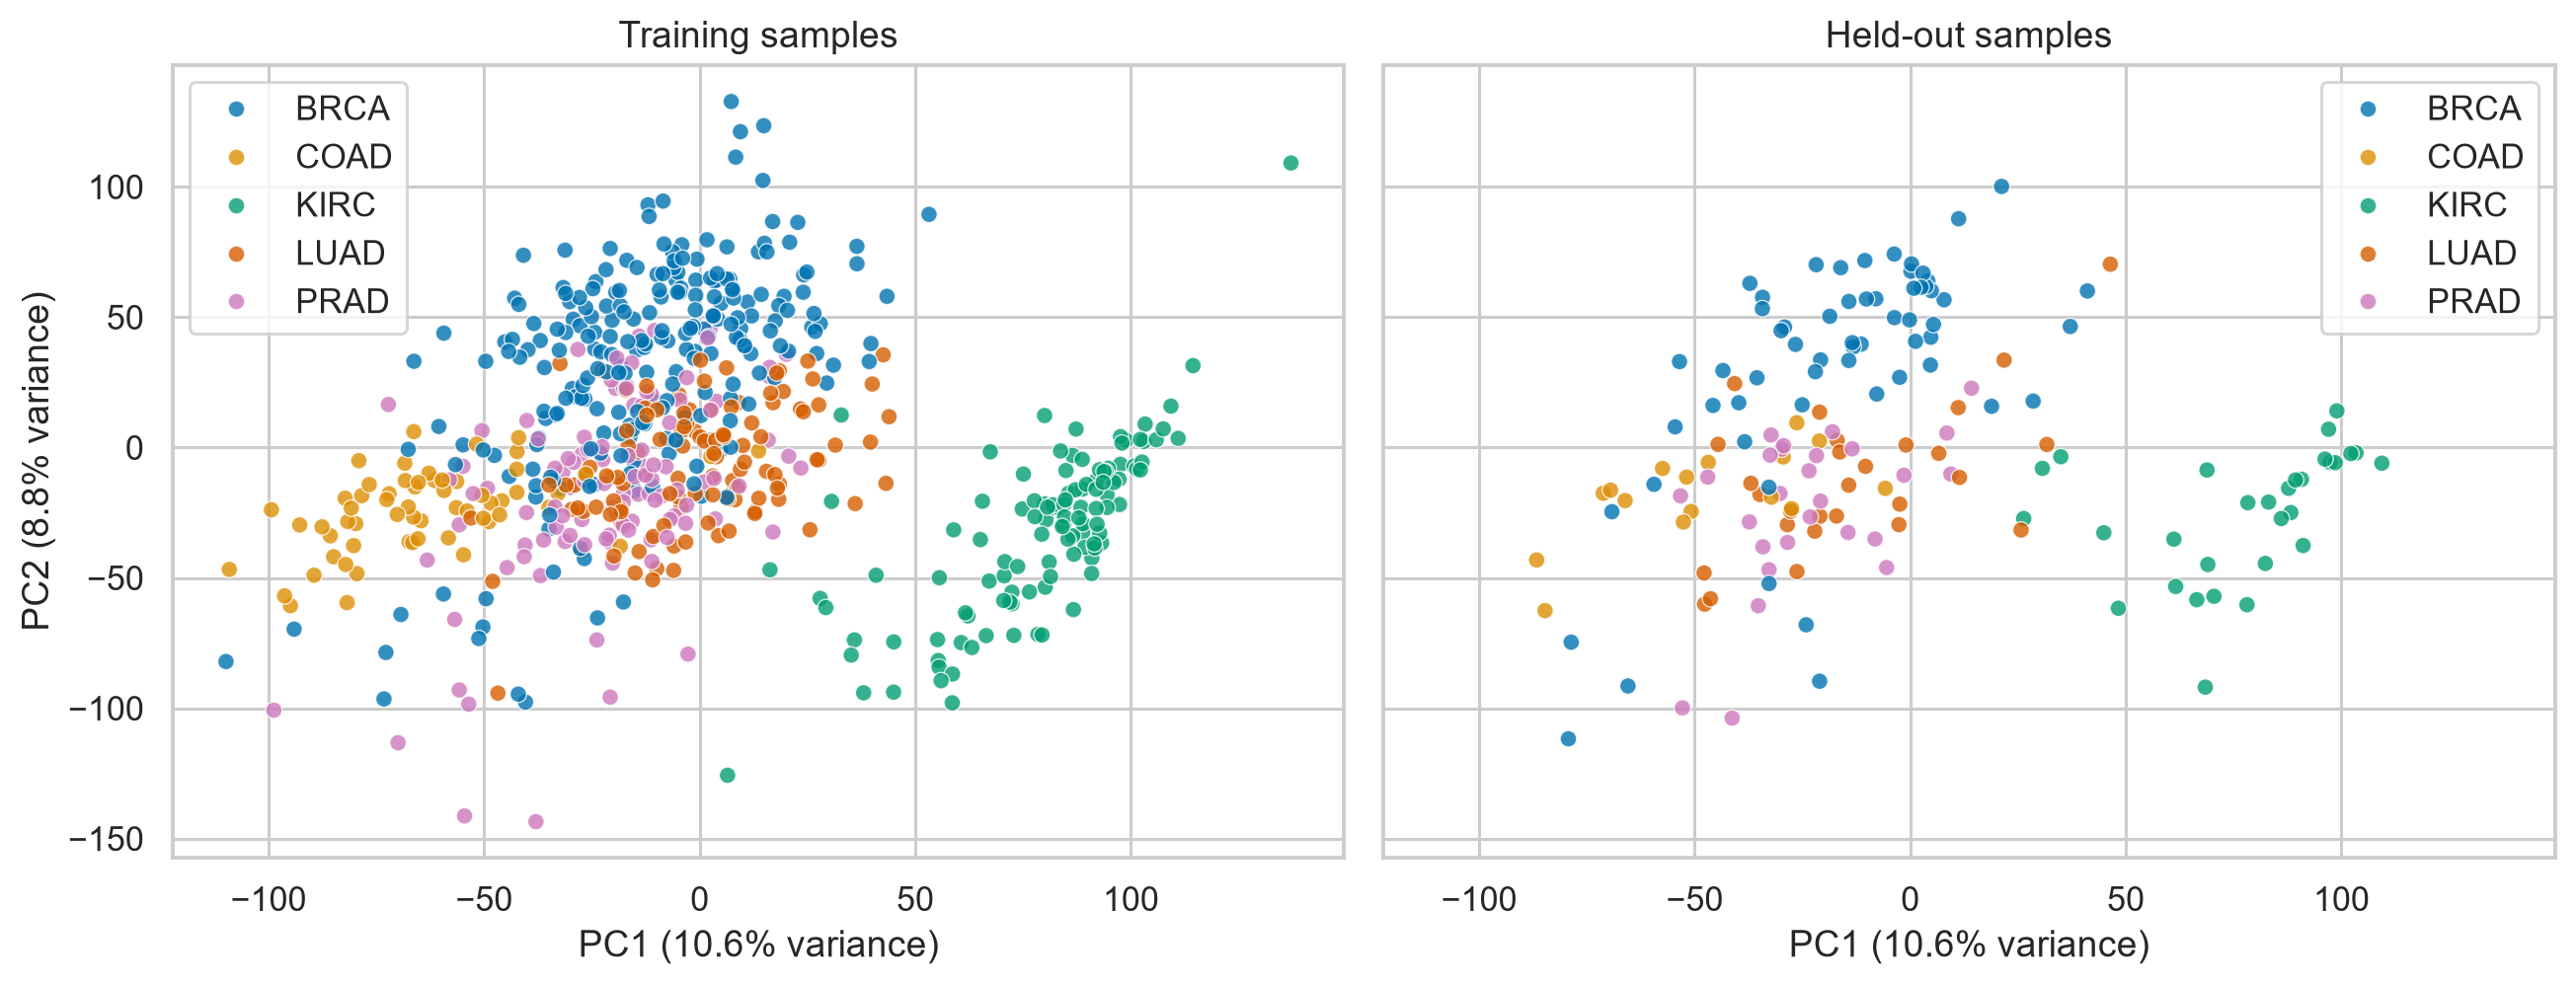

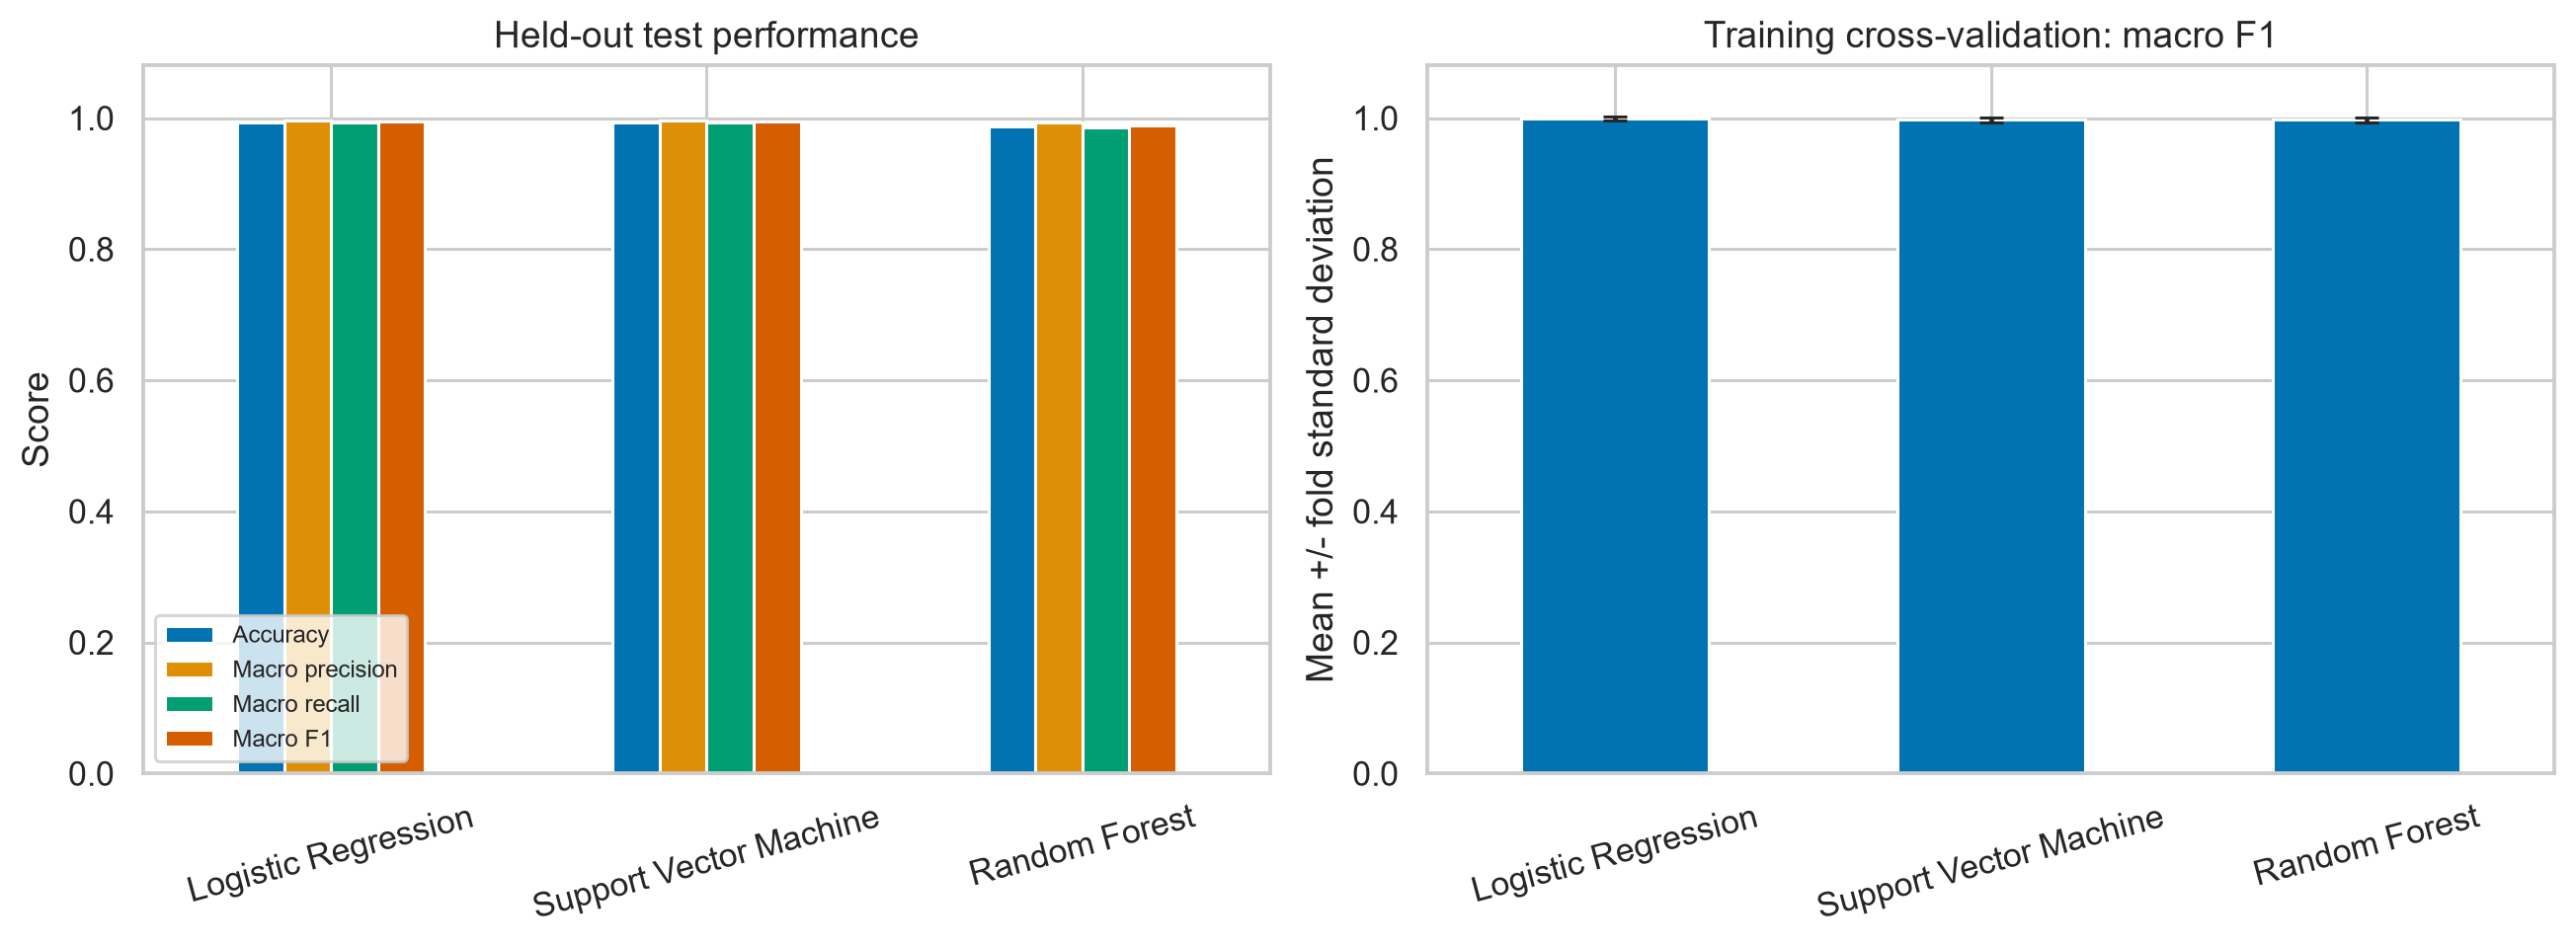

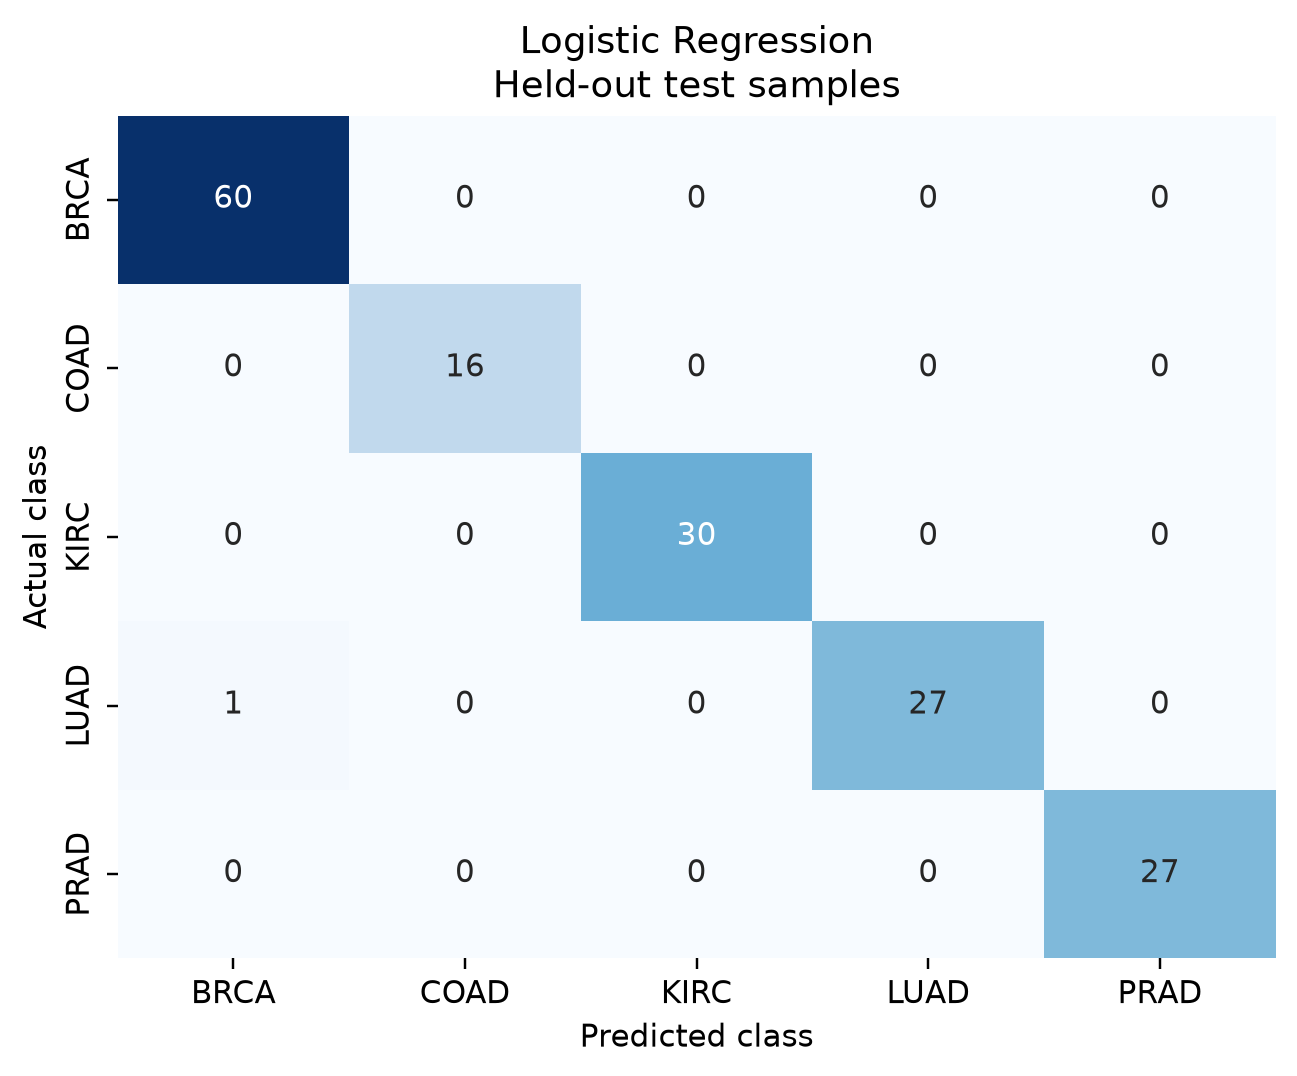

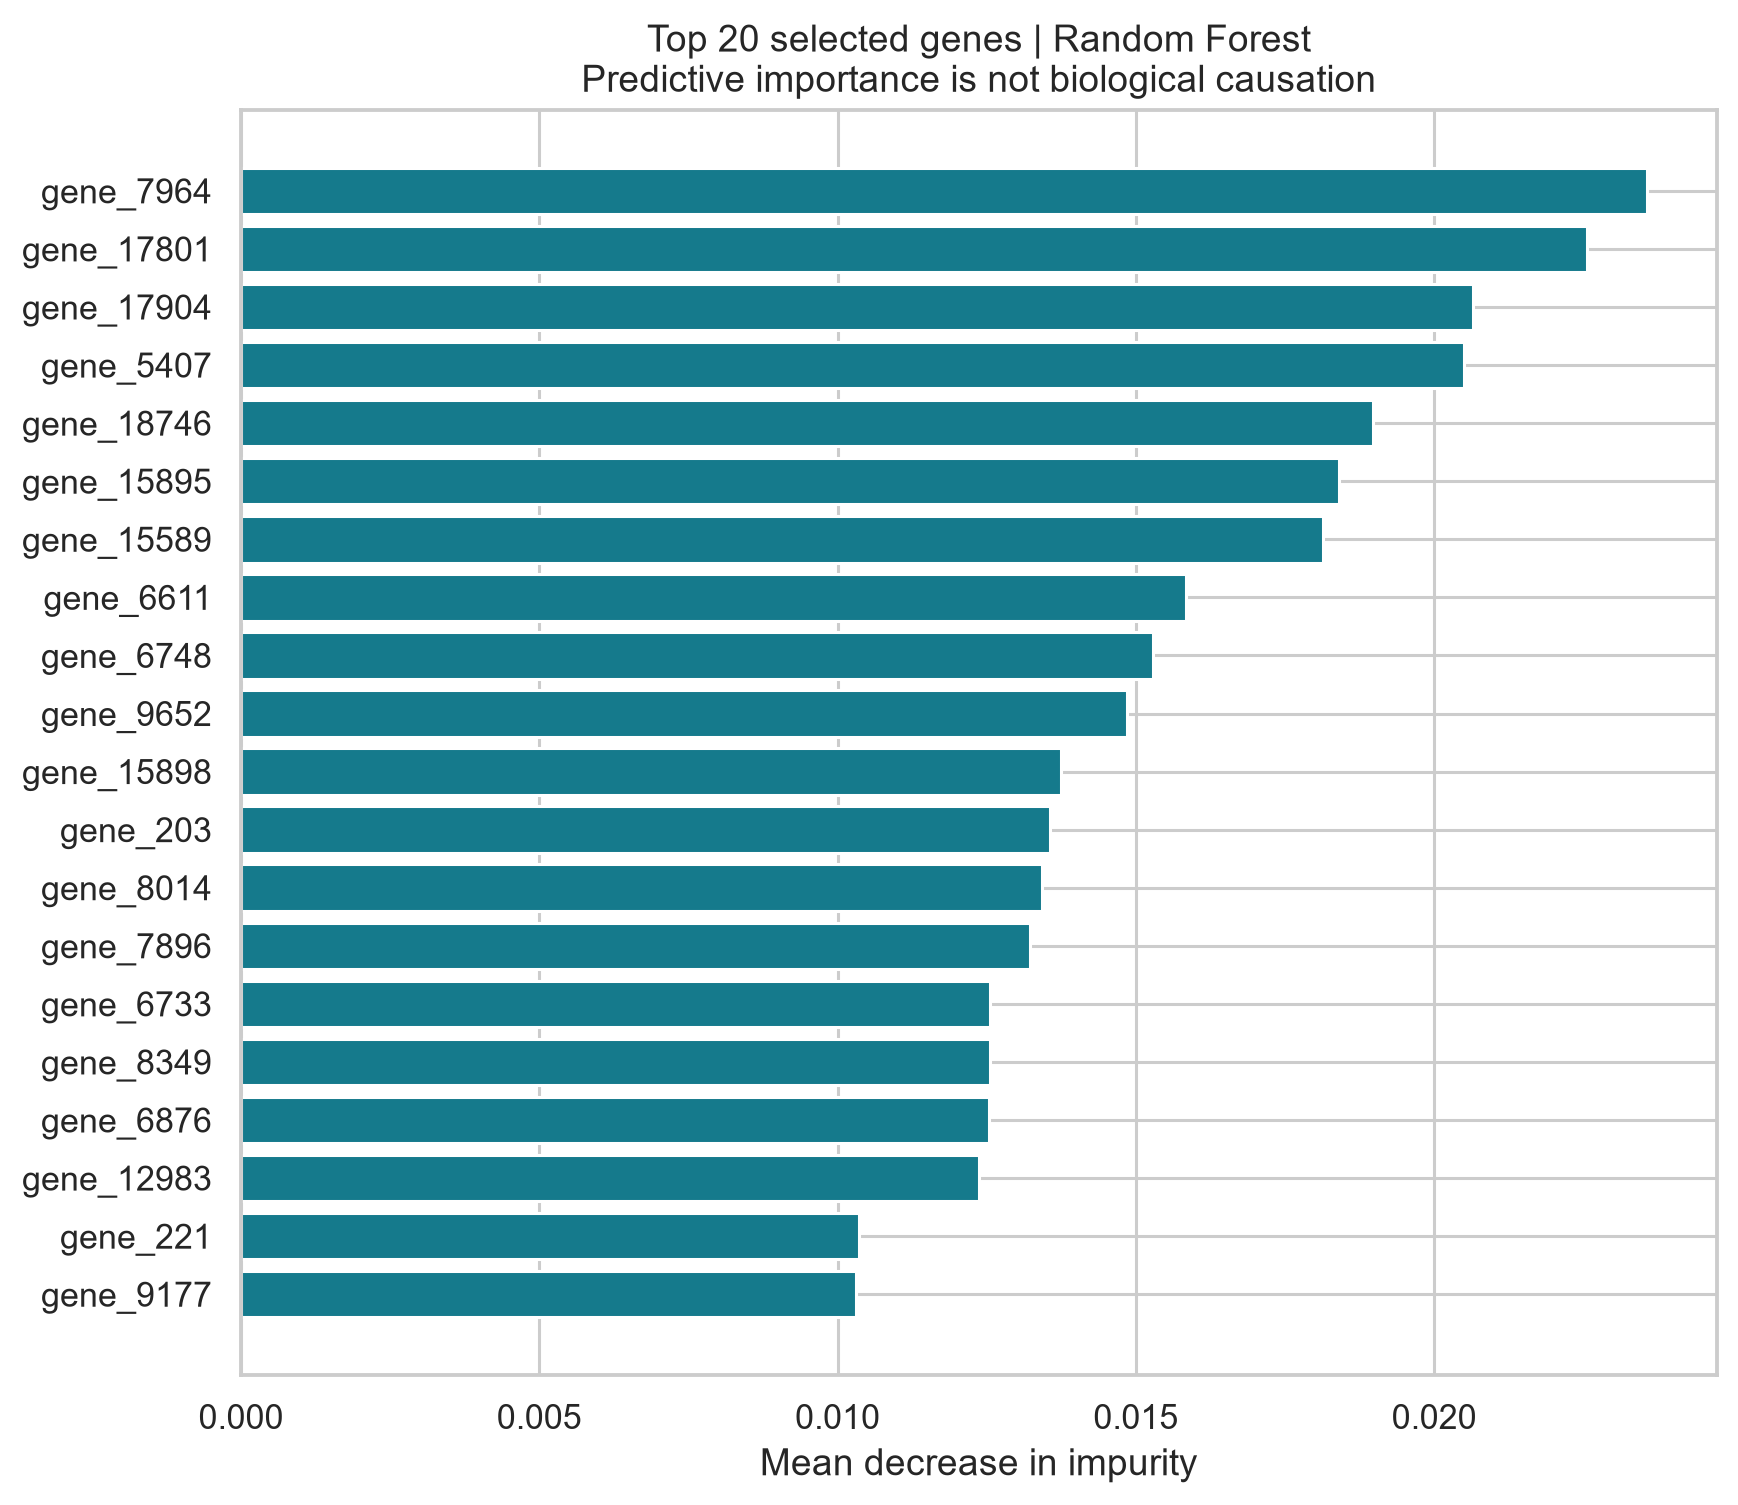

In [7]:
make_visualizations(X_train, X_test, y_train, y_test, encoder, y, fitted, metrics, cv_summary, best)
for name in ['class_distribution', 'pca_visualization', 'model_comparison', 'confusion_' + best.lower().replace(' ', '_'), 'top_genes']:
    display(Image(filename=str(FIGURES / (name + '.png')), width=850))

## 8. Save environment and generate the academic report
The report reads the actual saved metrics and includes the complete methods, results, discussion, limitations and references. The model remains fitted on the training subset, matching its evaluated state. Exact package versions document this run.

In [8]:
environment = {'python': platform.python_version(), 'packages': {p: version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','seaborn','ucimlrepo','joblib']}, 'seed': SEED, 'test_size': .2, 'cv_folds': 5, 'selected_genes': K_GENES, 'train_samples': len(X_train), 'test_samples': len(X_test)}
(TABLES / 'environment.json').write_text(json.dumps(environment, indent=2))
from build_report import build_report
build_report()

Report generated: C:\Users\PehAttaJoseph\Documents\ChatGPT\bio-informatics-Uner\output\pdf\academic_report.pdf


## 9. Interpretation and limitations
High internal accuracy shows association with supplied labels, not clinical utility. Tissue identity, batch effects and other unmeasured factors may contribute. The cohort lacks healthy controls and an independent external validation set. Anonymous gene labels prevent verified pathway or gene-function interpretation. Many more genes than samples make dimensionality control important, but this experiment does not prove that 500 genes is optimal. A single split and five folds do not demonstrate general superiority. The report gives the selected model and actual observed values; no result should be used as medical diagnosis.